# Lecture 6 Demo: Fit a Color Matrix, Then Break It

**Instructor demo.** About fifteen seconds, no external files.

Two things:

1. Fit a color correction matrix from a chart and watch $\Delta E$ collapse.
2. Construct a **metamer**: two surfaces the eye cannot tell apart that the camera
   reports as different colors. That is the residual you could not fit away.

In [4]:
import sys
from pathlib import Path

# Put the shared slide helpers on the path, wherever this notebook is opened from.
for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (parent / "psu_imaging.py").exists():
        sys.path.insert(0, str(parent))
        break

import cv2
import matplotlib.pyplot as plt
import numpy as np
import psu_imaging as psu

plt.rcParams.update(psu.figure_style())
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(513)
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.5.3


In [5]:
import sys
sys.path.insert(0, str(next(p for p in [__import__("pathlib").Path.cwd(), *__import__("pathlib").Path.cwd().parents]
                            if (p / "make_figures.py").exists())))
from make_figures import (LAMBDA, CMF, CAM, D65, integrate, cie_1931,
                          camera_sensitivities, illuminant_d65, illuminant_tungsten,
                          build_metamer, chart_responses, fit_ccm)

np.seterr(divide="ignore", over="ignore", invalid="ignore")   # spurious macOS BLAS flags
print(f"{len(LAMBDA)} wavelengths, {LAMBDA[0]:.0f} to {LAMBDA[-1]:.0f} nm")

StopIteration: 

## 1. Two observers

The eye integrates a spectrum against the CIE color matching functions. The camera
integrates the same spectrum against its color filter array. Both produce three numbers.
They are not the same three numbers, and no fixed matrix relates them for every spectrum.

NameError: name 'CMF' is not defined

findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.
findfont: Font family 'Helvetica Neue' not found.


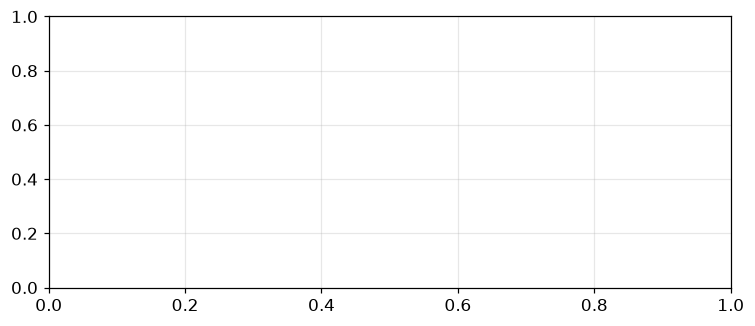

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for row, c, ls, lab in zip(CMF, ["#c0392b", psu.PSU_GREEN, psu.PSU_BLUE], ["-"] * 3,
                           [r"$\bar{x}$", r"$\bar{y}$", r"$\bar{z}$"]):
    ax.plot(LAMBDA, row / row.max(), ls, lw=2, color=c, label="eye " + lab)
for row, c, lab in zip(CAM, ["#c0392b", psu.PSU_GREEN, psu.PSU_BLUE], ["R", "G", "B"]):
    ax.plot(LAMBDA, row / row.max(), "--", lw=1.6, color=c, alpha=0.75, label="camera " + lab)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("normalized response")
ax.legend(fontsize=8, ncol=2); ax.set_xlim(390, 730)
ax.set_title("Two observers looking at the same light")
plt.tight_layout(); plt.show()

## 2. Fit the matrix

Twenty-four patches, nine unknowns. White balance first so the neutral patch is neutral,
then least squares from white-balanced camera RGB to XYZ.

In [ ]:
cam, xyz = chart_responses()
white = xyz[18]                                     # the white patch

gains = cam[18].max() / cam[18]                     # von Kries white balance
balanced = cam * gains

M = fit_ccm(balanced, xyz)
print("fitted color correction matrix (camera RGB -> XYZ):")
print(np.array2string(M, precision=4, suppress_small=True))
print(f"\nrow sums {np.round(M.sum(axis=1), 3).tolist()}  "
      "(close to preserving neutrals without being constrained to)")

lab_true = psu.xyz_to_lab(xyz, white)
de_wb = psu.delta_e_76(psu.xyz_to_lab(psu.linear_rgb_to_xyz(balanced), white), lab_true)
de_ccm = psu.delta_e_76(psu.xyz_to_lab(balanced @ M.T, white), lab_true)

print(f"\n{'':22s} {'mean':>7} {'worst':>7}")
print(f"{'white balance only':22s} {de_wb.mean():7.2f} {de_wb.max():7.2f}")
print(f"{'plus 3x3 matrix':22s} {de_ccm.mean():7.2f} {de_ccm.max():7.2f}")

In [ ]:
def to_srgb_patches(xyz_vals):
    lin = np.clip(xyz_vals @ np.linalg.inv(psu.SRGB_TO_XYZ).T, 0, 1)
    return np.clip(psu.linear_to_srgb(lin), 0, 1).reshape(4, 6, 3)

fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
for ax, vals, title in zip(
        axes,
        [xyz, psu.linear_rgb_to_xyz(balanced), balanced @ M.T],
        ["Truth", f"White balance only ($\\Delta E$ {de_wb.mean():.1f})",
         f"With matrix ($\\Delta E$ {de_ccm.mean():.2f})"]):
    ax.imshow(to_srgb_patches(vals)); ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout(); plt.show()

worst = np.argsort(de_ccm)[-3:][::-1]
print("worst three patches after fitting:")
for i in worst:
    print(f"  {psu.COLORCHECKER_NAMES[i]:16s} dE = {de_ccm[i]:.2f}")

## 3. Why the residual never reaches zero

A matrix can only be exact if the camera's sensitivities are a linear combination of the
color matching functions. That is the **Luther condition**, and no real camera satisfies it.

Here is the proof, constructed. We find a perturbation that lives in the null space of the
observer matrix, so the eye cannot see it at all, and we pick the one the camera responds
to most strongly.

In [ ]:
s1, s2 = build_metamer()

xyz1 = integrate(s1, CMF, D65)[0]
xyz2 = integrate(s2, CMF, D65)[0]
rgb1 = integrate(s1, CAM, D65)[0]
rgb2 = integrate(s2, CAM, D65)[0]

w = integrate(np.ones_like(LAMBDA), CMF, D65)[0]
de = float(psu.delta_e_76(psu.xyz_to_lab(xyz1 / w[1], w / w[1]),
                          psu.xyz_to_lab(xyz2 / w[1], w / w[1])))

print(f"XYZ of surface A   {np.round(xyz1, 5).tolist()}")
print(f"XYZ of surface B   {np.round(xyz2, 5).tolist()}")
print(f"difference to the eye:    dE76 = {de:.4f}")
print()
print(f"camera RGB of A    {np.round(rgb1, 4).tolist()}")
print(f"camera RGB of B    {np.round(rgb2, 4).tolist()}")
rel = np.abs(rgb2 - rgb1) / np.maximum(rgb1, 1e-12) * 100
print(f"difference to the camera: {np.round(rel, 1).tolist()} % per channel")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(LAMBDA, s1, lw=2, color=psu.PSU_BLUE, label="surface A")
axes[0].plot(LAMBDA, s2, lw=2, color=psu.PSU_WARM, label="surface B")
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_ylabel("reflectance")
axes[0].set_title(f"Identical to the eye: $\\Delta E$ = {de:.3f}")
axes[0].legend(fontsize=9); axes[0].set_xlim(390, 730); axes[0].set_ylim(0, 1)

x = np.arange(3)
axes[1].bar(x - 0.18, rgb1, 0.36, color=psu.PSU_BLUE, label="A")
axes[1].bar(x + 0.18, rgb2, 0.36, color=psu.PSU_WARM, label="B")
axes[1].set_xticks(x); axes[1].set_xticklabels(["R", "G", "B"])
axes[1].set_title("Different to the camera"); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

print("No 3x3 matrix can map both of these to the same XYZ, because they already have")
print("the same XYZ and different RGB. That is the irreducible part of the residual.")

## 4. The matrix is tied to its illuminant

Fit under daylight, shoot under tungsten, and the colors drift. This is why cameras carry
several matrices and interpolate between them by estimated color temperature.

In [ ]:
tung = illuminant_tungsten()

basis = np.stack([np.exp(-0.5 * ((LAMBDA - mu) / 55.0) ** 2) for mu in (450., 540., 610.)])
A = integrate(basis, CMF, D65)
weights = np.linalg.solve(A.T, psu.linear_rgb_to_xyz(psu.srgb_to_linear(psu.COLORCHECKER_SRGB)).T).T
spectra = np.clip(weights @ basis, 0, None)

cam_t = integrate(spectra, CAM, tung); xyz_t = integrate(spectra, CMF, tung)
cam_t, xyz_t = cam_t / xyz_t[18, 1], xyz_t / xyz_t[18, 1]
gains_t = cam_t[18].max() / cam_t[18]

de_wrong = psu.delta_e_76(psu.xyz_to_lab((cam_t * gains_t) @ M.T, xyz_t[18]),
                          psu.xyz_to_lab(xyz_t, xyz_t[18]))
M_t = fit_ccm(cam_t * gains_t, xyz_t)
de_right = psu.delta_e_76(psu.xyz_to_lab((cam_t * gains_t) @ M_t.T, xyz_t[18]),
                          psu.xyz_to_lab(xyz_t, xyz_t[18]))

print(f"white balance gains: daylight {np.round(gains, 2).tolist()}, "
      f"tungsten {np.round(gains_t, 2).tolist()}")
print(f"\nunder tungsten, daylight matrix: mean dE {de_wrong.mean():.2f}, worst {de_wrong.max():.2f}")
print(f"under tungsten, tungsten matrix: mean dE {de_right.mean():.2f}, worst {de_right.max():.2f}")
print("\nNote the blue gain. Large gains amplify that channel's noise along with the signal,")
print("which is why tungsten plus low light is where cameras look worst.")

## 5. The average of black and white

Ask the room before running this.

In [ ]:
black, white_v = 0.0, 1.0
naive = (black + white_v) / 2
correct = psu.linear_to_srgb((psu.srgb_to_linear(black) + psu.srgb_to_linear(white_v)) / 2)
print(f"average of the encoded values : {naive:.3f}")
print(f"average of the light, encoded : {correct:.3f}")

n, block = 256, 8
yy, xx = np.mgrid[0:n, 0:n]
checker = ((xx // 2 + yy // 2) % 2).astype(float)
wrong = checker.reshape(n // block, block, n // block, block).mean(axis=(1, 3))
right = psu.linear_to_srgb(psu.srgb_to_linear(checker)
                           .reshape(n // block, block, n // block, block).mean(axis=(1, 3)))

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, img, t in zip(axes, [checker[:64, :64], wrong, right],
                      ["Original checkerboard", f"Downsampled in sRGB ({wrong.mean():.2f})",
                       f"Downsampled in linear light ({right.mean():.2f})"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1); ax.set_title(t, fontsize=9.5); ax.axis("off")
plt.tight_layout(); plt.show()

## Back to the slides

Three things to land:

1. A color matrix takes mean $\Delta E$ from 16 to well under 1 on this data. Fit it.
2. The residual has a floor, and the floor is metamerism, not a bad optimizer.
3. Do the arithmetic in linear light. The average of black and white is 0.73.

Next: lecture 7 puts white balance, demosaicing, and the color matrix into an order, and
the order turns out to matter.